# 02 · Selección de modelos

**Pregunta de negocio:** al **10 de febrero** de cada campaña, ¿qué rendimiento de soja (kg/ha) va a tener cada departamento?
Con eso la aseguradora puede estimar cuánto va a tener que pagar y reservar a tiempo.

Este notebook **compara muchos modelos y elige uno**. Reglas que se respetan en todo el notebook:

| Regla | Cómo se cumple |
|---|---|
| El **test (2020/21 – 2024/25) no se toca** | Acá solo se usan campañas ≤ 2019/20. Hay un `assert` que lo garantiza. |
| Sin fuga de información | Solo ventanas climáticas cerradas al 10/02 (barbecho, siembra, vegetativo, floración). Nada de producción ni superficie cosechada. |
| Todo lo que "aprende" de los datos se calcula **dentro de cada fold** | Promedio del departamento, tendencia, etc. se calculan solo con el train del fold (ver `comun.py`). |

### Cómo se valida: ventana expansiva

Como el problema es temporal, **no** se mezclan años al azar: siempre se entrena con el pasado y se evalúa en el año siguiente.

```
fold 2010:  entrena 1999 … 2009  →  valida 2010
fold 2011:  entrena 1999 … 2010  →  valida 2011
   …
fold 2019:  entrena 1999 … 2018  →  valida 2019
```

Son **10 folds** (2010 a 2019). Incluyen la **sequía 2017/18**, así que vemos cómo le va a cada modelo en un año malo.

### Métricas (todas en kg/ha)

- **RMSE** (métrica principal): castiga más los errores grandes, que son los que le hacen daño a la aseguradora.
- **MAE**: error promedio "típico", fácil de explicar.
- **Sesgo** = promedio de (predicho − real). **Negativo**: el modelo predice de menos. **Positivo**: predice de más.
- **RMSE en sequía (2017/18)** y **sesgo en sequía**: el año que más importa al negocio.
- **Mejora %** respecto del baseline "promedio histórico del departamento".

In [1]:
import time, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, HuberRegressor
from sklearn.cross_decomposition import PLSRegression
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

from comun import *          # reglas anti-fuga, validación y modelo (ver notebooks/comun.py)

estilo_graficos()
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)
N_JOBS = 8                   # folds en paralelo (bajarlo si la compu tiene menos núcleos)

d = cargar()
train = d[d.anio <= ULTIMO_TRAIN].copy()
assert train.anio.max() == ULTIMO_TRAIN and not set(TEST) & set(train.anio), "el test no puede estar acá"
print(f"Train: {len(train):,} filas, campañas {train.anio.min()}/{train.anio.min()+1 - 2000:02d} a "
      f"{train.anio.max()}/{train.anio.max()+1 - 2000:02d}, {train.departamento_id.nunique()} departamentos")

Train: 4,906 filas, campañas 1999/00 a 2019/20, 255 departamentos


In [2]:
# Cómo quedan los 10 folds
pd.DataFrame([{"fold (año validado)": v, "entrena con": f"{tr.anio.min()}–{tr.anio.max()}",
               "filas train": len(tr), "filas validación": len(va)}
              for v, tr, va in folds_expansivos(train)])

,fold (año validado),entrena con,filas train,filas validación
0,2010,1999–2009,2404,253
1,2011,1999–2010,2657,246
2,2012,1999–2011,2903,250
3,2013,1999–2012,3153,250
4,2014,1999–2013,3403,251
5,2015,1999–2014,3654,250
6,2016,1999–2015,3904,250
7,2017,1999–2016,4154,248
8,2018,1999–2017,4402,252
9,2019,1999–2018,4654,252


In [3]:
filas, preds = [], {}
BASE = None          # RMSE del baseline "media del depto"; se completa en la primera prueba

def probar(seccion, nombre, modelo):
    # Corre la validación expansiva completa y guarda las métricas
    t = time.time()
    p = validar(modelo, train, n_jobs=N_JOBS)
    preds[nombre] = p
    r = resumen(p, nombre, BASE)
    r.update(seccion=seccion, seg=round(time.time() - t))
    filas.append(r)
    mejora = f"{r['mejora_pct']:+5.1f}%" if BASE else "  (ref)"
    print(f"{nombre:46s} RMSE={r['rmse_cv']:6.1f}  MAE={r['mae_cv']:6.1f}  sesgo={r['sesgo']:+6.1f}  "
          f"sequía={r['rmse_2017_sequia']:6.1f}  {mejora}  ({r['seg']}s)")
    return r

COLS = ["modelo", "rmse_cv", "mae_cv", "sesgo", "rmse_2017_sequia", "sesgo_sequia", "mejora_pct"]
def tabla(seccion):
    t = pd.DataFrame(filas)
    return t[t.seccion == seccion].sort_values("rmse_cv")[COLS].round(1).reset_index(drop=True)

esc = lambda *pasos: make_pipeline(StandardScaler(), *pasos)      # escalar antes de modelos lineales
lasso = lambda a: esc(Lasso(alpha=a, max_iter=100000))
REL = lambda est, **kw: ModeloRendimiento(est, "relativo", usar_dep=False, **kw)    # lineales
REL_ARB = lambda est, **kw: ModeloRendimiento(est, "relativo", extras=("acum", "region"), **kw)  # árboles

## 1. Baselines: lo mínimo que hay que superar

Modelos "sin inteligencia". Si un modelo no les gana, no sirve.

- **Promedio general:** el mismo número para todos.
- **Campaña anterior:** "este año va a rendir lo mismo que el año pasado".
- **Media del departamento:** el promedio histórico de cada departamento (es **el baseline de referencia**).
- **Departamento + tendencia:** el promedio del departamento más una pendiente por año (la soja rinde cada vez más por mejoras tecnológicas).

In [4]:
r = probar("1 baselines", "Baseline: media del depto", ModeloRendimiento(None, "media_dep"))
BASE = r["rmse_cv"]; filas[-1]["mejora_pct"] = 0.0
probar("1 baselines", "Baseline: promedio general", ModeloRendimiento(None, "media_global"))
probar("1 baselines", "Baseline: campaña anterior", ModeloRendimiento(None, "anterior"))
probar("1 baselines", "Baseline: depto + tendencia", ModeloRendimiento(None, "tendencia"))
tabla("1 baselines")

Baseline: media del depto                      RMSE= 650.6  MAE= 530.6  sesgo=-241.9  sequía= 605.1    (ref)  (10s)


Baseline: promedio general                     RMSE= 802.7  MAE= 638.6  sesgo=-243.0  sequía= 669.3  -23.4%  (1s)


Baseline: campaña anterior                     RMSE= 729.2  MAE= 569.4  sesgo=  -0.7  sequía= 978.9  -12.1%  (1s)


Baseline: depto + tendencia                    RMSE= 608.5  MAE= 487.6  sesgo= -89.0  sequía= 761.9   +6.5%  (1s)


,modelo,rmse_cv,mae_cv,sesgo,rmse_2017_sequia,sesgo_sequia,mejora_pct
0,Baseline: depto + tendencia,608.5,487.6,-89.0,761.9,478.0,6.5
1,Baseline: media del depto,650.6,530.6,-241.9,605.1,173.3,0.0
2,Baseline: campaña anterior,729.2,569.4,-0.7,978.9,746.5,-12.1
3,Baseline: promedio general,802.7,638.6,-243.0,669.3,173.2,-23.4


**Lectura:** la media del departamento (≈ 651) ya es bastante mejor que el promedio general, porque *dónde* se siembra explica mucho.
Sumarle la tendencia baja el error a ≈ 609, pero en la sequía empeora: la tendencia "promete" más rinde justo el año en que cae.

## 2. ¿Qué le pedimos que prediga? (cambio de target)

Mismo modelo (Lasso), distintas formas de plantear el objetivo:

| Target | Qué predice el modelo |
|---|---|
| crudo | el rendimiento directamente (kg/ha) |
| desvío vs media del depto | cuánto se aparta del promedio de su departamento |
| residuo | cuánto se aparta de *departamento + tendencia* |
| **relativo** | ese mismo desvío pero **en % del rendimiento esperado** del departamento |

La idea del **relativo**: una sequía no saca "500 kg/ha" en todos lados, saca **un porcentaje**. Un 20 % de caída en un departamento que rinde 3.500 son 700 kg; en uno que rinde 2.000 son 400 kg. Expresarlo en % hace que el mismo efecto del clima sirva para todos los departamentos.

In [5]:
probar("2 target", "Lasso crudo (a=20)", ModeloRendimiento(lasso(20), "crudo"))
probar("2 target", "Lasso desvío vs media depto (a=20)", ModeloRendimiento(lasso(20), "desvio_media", usar_dep=False))
probar("2 target", "Lasso residuo sin tendencia (a=20)", ModeloRendimiento(lasso(20), "residuo", usar_dep=False))
probar("2 target", "Lasso relativo (a=0.012)", REL(lasso(.012)))
tabla("2 target")

Lasso crudo (a=20)                             RMSE= 528.9  MAE= 428.6  sesgo= -63.9  sequía= 590.2  +18.7%  (2s)


Lasso desvío vs media depto (a=20)             RMSE= 531.8  MAE= 430.1  sesgo= -95.7  sequía= 568.7  +18.3%  (1s)


Lasso residuo sin tendencia (a=20)             RMSE= 526.1  MAE= 425.3  sesgo= -50.1  sequía= 605.6  +19.1%  (1s)


Lasso relativo (a=0.012)                       RMSE= 518.7  MAE= 418.8  sesgo= -49.9  sequía= 569.0  +20.3%  (1s)


,modelo,rmse_cv,mae_cv,sesgo,rmse_2017_sequia,sesgo_sequia,mejora_pct
0,Lasso relativo (a=0.012),518.7,418.8,-49.9,569.0,218.6,20.3
1,Lasso residuo sin tendencia (a=20),526.1,425.3,-50.1,605.6,274.5,19.1
2,Lasso crudo (a=20),528.9,428.6,-63.9,590.2,245.2,18.7
3,Lasso desvío vs media depto (a=20),531.8,430.1,-95.7,568.7,200.4,18.3


**Lectura:** el target **relativo** es el mejor (≈ 519 contra 526–532). Desde acá **todos los modelos usan el target relativo** (salvo KNN y MLP, que se probaron en la primera ronda con el residuo).

> El `alpha` cambia de escala (20 vs 0.012) porque el target relativo está en proporción (0.10 = 10 %) y no en kg/ha.

## 3. Familias de modelos

Un representante bien configurado de cada familia (la configuración sale de búsquedas de hiperparámetros en las rondas exploratorias; ver `resultados/rondas_validacion/`).

- **Lineales:** regresión lineal, Ridge (encoge coeficientes), Lasso (encoge y pone en cero los que no sirven), ElasticNet (mezcla de los dos), Huber (robusta a outliers), PLS y PCA + Ridge (resumen las variables climáticas en pocos componentes), efectos fijos (una variable dummy por departamento).
- **No lineales "de distancia":** KNN, SVR, red neuronal (MLP).
- **Árboles:** Random Forest, Extra Trees, HistGradientBoosting, LightGBM, XGBoost, CatBoost. Los árboles **no pueden extrapolar el año** (no saben que 2019 rinde más que 2000), por eso el target relativo, que ya trae la tendencia descontada, les sirve mucho.

In [6]:
S = "3 familias"
# Lineales
probar(S, "Regresión lineal sin regularizar", REL(esc(LinearRegression())))
probar(S, "Ridge (a=3000)", REL(esc(Ridge(alpha=3000))))
probar(S, "Lasso (a=0.012)", REL(lasso(.012)))
probar(S, "ElasticNet (a=0.025, l1=0.5)", REL(esc(ElasticNet(alpha=.025, l1_ratio=.5, max_iter=100000))))
probar(S, "Huber robusta (a=1000)", REL(esc(HuberRegressor(alpha=1000, max_iter=2000))))
probar(S, "PLS (4 componentes)", REL(esc(PLSRegression(n_components=4, scale=False))))
probar(S, "PCA(20) + Ridge", REL(esc(PCA(20), Ridge(alpha=10))))
probar(S, "Efectos fijos: Ridge + dummies depto (crudo)",
       ModeloRendimiento(esc(Ridge(alpha=1000)), "crudo", usar_dep=False, extras=("dummies_dep",)))
# Distancia / redes
probar(S, "KNN (k=25, residuo)", ModeloRendimiento(esc(KNeighborsRegressor(n_neighbors=25)), "residuo"))
probar(S, "SVR (C=0.1)", REL(esc(SVR(C=.1, epsilon=.05))))
probar(S, "Red neuronal MLP (64-32, residuo)", ModeloRendimiento(esc(MLPRegressor(
    hidden_layer_sizes=(64, 32), alpha=1.0, max_iter=600, early_stopping=True, random_state=0)), "residuo"))

Regresión lineal sin regularizar               RMSE= 615.8  MAE= 489.3  sesgo=-142.5  sequía= 519.2   +5.3%  (1s)


Ridge (a=3000)                                 RMSE= 533.8  MAE= 430.0  sesgo= -71.0  sequía= 526.5  +18.0%  (1s)


Lasso (a=0.012)                                RMSE= 518.7  MAE= 418.8  sesgo= -49.9  sequía= 569.0  +20.3%  (1s)


ElasticNet (a=0.025, l1=0.5)                   RMSE= 518.9  MAE= 418.5  sesgo= -49.0  sequía= 575.0  +20.2%  (1s)


Huber robusta (a=1000)                         RMSE= 562.7  MAE= 454.0  sesgo=-100.9  sequía= 504.2  +13.5%  (3s)


PLS (4 componentes)                            RMSE= 536.3  MAE= 435.0  sesgo= -72.0  sequía= 507.5  +17.6%  (1s)


... (2 outputs left out)

KNN (k=25, residuo)                            RMSE= 609.2  MAE= 477.5  sesgo= -30.5  sequía= 762.4   +6.4%  (1s)


SVR (C=0.1)                                    RMSE= 568.1  MAE= 451.5  sesgo= -66.2  sequía= 559.0  +12.7%  (6s)


Red neuronal MLP (64-32, residuo)              RMSE= 619.1  MAE= 482.2  sesgo= +26.4  sequía= 559.2   +4.9%  (20s)


{'modelo': 'Red neuronal MLP (64-32, residuo)',
 'rmse_cv': 619.0595165324306,
 'mae_cv': 482.18046131963115,
 'sesgo': 26.430369299788318,
 'rmse_medio_folds': 613.4555499829751,
 'rmse_peor_fold': 761.3855698570756,
 'rmse_2017_sequia': 559.197692007975,
 'sesgo_sequia': -60.284899988719324,
 'mejora_pct': 4.852746282902687,
 'seccion': '3 familias',
 'seg': 20}

In [7]:
# Árboles (con acumulados de la campaña y promedio provincial del clima)
probar(S, "Random Forest", REL_ARB(RandomForestRegressor(300, min_samples_leaf=20, max_features=.15,
                                                         n_jobs=1, random_state=0)))
probar(S, "Extra Trees", REL_ARB(ExtraTreesRegressor(300, min_samples_leaf=20, max_features=.25,
                                                     n_jobs=1, random_state=0)))
probar(S, "HistGradientBoosting", REL_ARB(HistGradientBoostingRegressor(learning_rate=.05, max_iter=400,
                                          min_samples_leaf=60, l2_regularization=1, random_state=0)))
probar(S, "LightGBM", REL_ARB(LGBMRegressor(n_estimators=600, learning_rate=.03, num_leaves=7, min_child_samples=40,
                              subsample=.8, subsample_freq=1, colsample_bytree=.5, reg_lambda=5,
                              n_jobs=1, random_state=0, verbose=-1)))
probar(S, "XGBoost", REL_ARB(XGBRegressor(n_estimators=600, learning_rate=.03, max_depth=3, subsample=.8,
                             colsample_bytree=.5, min_child_weight=5, reg_lambda=5, n_jobs=1, random_state=0)))
probar(S, "CatBoost", REL_ARB(CatBoostRegressor(iterations=800, learning_rate=.05, depth=4, verbose=0,
                              thread_count=1, random_seed=0, allow_writing_files=False)))
tabla(S)

Random Forest                                  RMSE= 536.4  MAE= 431.7  sesgo= -53.4  sequía= 629.3  +17.6%  (22s)


Extra Trees                                    RMSE= 543.3  MAE= 436.6  sesgo= -53.2  sequía= 659.5  +16.5%  (9s)


HistGradientBoosting                           RMSE= 555.4  MAE= 451.4  sesgo= -76.2  sequía= 625.1  +14.6%  (27s)


LightGBM                                       RMSE= 542.3  MAE= 439.2  sesgo= -59.5  sequía= 558.3  +16.7%  (5s)


XGBoost                                        RMSE= 546.7  MAE= 438.2  sesgo= -46.6  sequía= 582.4  +16.0%  (11s)


CatBoost                                       RMSE= 535.9  MAE= 427.3  sesgo= -50.6  sequía= 522.2  +17.6%  (47s)


,modelo,rmse_cv,mae_cv,sesgo,rmse_2017_sequia,sesgo_sequia,mejora_pct
0,Lasso (a=0.012),518.7,418.8,-49.9,569.0,218.6,20.3
1,"ElasticNet (a=0.025, l1=0.5)",518.9,418.5,-49.0,575.0,231.1,20.2
2,PCA(20) + Ridge,528.7,428.6,-27.5,519.4,118.4,18.7
3,Ridge (a=3000),533.8,430.0,-71.0,526.5,161.3,18.0
4,CatBoost,535.9,427.3,-50.6,522.2,142.2,17.6
5,PLS (4 componentes),536.3,435.0,-72.0,507.5,87.2,17.6
6,Random Forest,536.4,431.7,-53.4,629.3,301.7,17.6
7,LightGBM,542.3,439.2,-59.5,558.3,215.2,16.7
8,Extra Trees,543.3,436.6,-53.2,659.5,341.5,16.5
9,XGBoost,546.7,438.2,-46.6,582.4,263.1,16.0


**Lectura:**
- Los **lineales regularizados** (Lasso, ElasticNet) quedan arriba. Hay ~90 variables climáticas muy correlacionadas entre sí (la temperatura media, la máxima y la ET0 se mueven juntas), y el Lasso se queda con unas pocas y descarta las redundantes.
- La **regresión sin regularizar** es mucho peor (≈ 616): con tantas variables correlacionadas, los coeficientes se disparan y sobreajusta.
- Entre los árboles, **CatBoost y Random Forest** quedan primeros (≈ 536), pero CatBoost es mucho mejor en la sequía (≈ 522 contra ≈ 629). Extra Trees, LightGBM, XGBoost y HGB quedan más atrás *con estos hiperparámetros* (en la sección 6 se ajustan con Optuna).
- KNN, SVR y la red neuronal no compiten: con ~4.000 filas y tantas variables, no tienen datos suficientes para aprender bien.

## 4. Features nuevas

Sobre el mejor lineal (Lasso relativo) y el mejor árbol (CatBoost) probamos agregar:

- **rezagos**: rendimiento de la campaña anterior y promedio de las últimas 3 (ya cosechadas al 10/02, así que no hay fuga) y cambio en la superficie sembrada.
- **interacciones**: floración seca **y** caliente al mismo tiempo (el peor escenario), lo mismo en el período vegetativo.
- **provincia** (target encoding con el train).
- **acumulados**: lluvia, balance hídrico y días de calor sumados en toda la campaña, y la racha seca más larga.
- **anomalías vs valores crudos**: ¿alcanza con el desvío respecto de lo normal, o hace falta el valor absoluto?

In [8]:
S = "4 features"
probar(S, "Lasso + rezagos", REL(lasso(.012), extras=("rezagos",)))
probar(S, "Lasso + interacciones", REL(lasso(.012), extras=("interac",)))
probar(S, "Lasso + provincia (target encoding)", REL(lasso(.012), extras=("prov_te",)))
probar(S, "Lasso + rezagos + interac + provincia", REL(lasso(.012), extras=("rezagos", "interac", "prov_te")))
probar(S, "Lasso SOLO anomalías", REL(lasso(.012), tipo_clima="anom"))
probar(S, "Lasso SOLO valores crudos", REL(lasso(.012), tipo_clima="crudo"))
CAT = lambda **kw: ModeloRendimiento(CatBoostRegressor(iterations=800, learning_rate=.05, depth=4, verbose=0,
                                     thread_count=1, random_seed=0, allow_writing_files=False), "relativo", **kw)
probar(S, "CatBoost + acum + region + rezagos + interac", CAT(extras=EXTRAS_ARBOLES))
tabla(S)

Lasso + rezagos                                RMSE= 516.9  MAE= 417.1  sesgo= -45.3  sequía= 569.4  +20.5%  (1s)


Lasso + interacciones                          RMSE= 522.5  MAE= 422.2  sesgo= -57.7  sequía= 566.4  +19.7%  (1s)


Lasso + provincia (target encoding)            RMSE= 518.7  MAE= 418.8  sesgo= -49.9  sequía= 569.0  +20.3%  (0s)


Lasso + rezagos + interac + provincia          RMSE= 520.8  MAE= 420.6  sesgo= -53.1  sequía= 565.9  +20.0%  (1s)


Lasso SOLO anomalías                           RMSE= 518.7  MAE= 418.7  sesgo= -49.7  sequía= 569.9  +20.3%  (0s)


Lasso SOLO valores crudos                      RMSE= 565.4  MAE= 449.8  sesgo= -55.2  sequía= 656.2  +13.1%  (0s)


CatBoost + acum + region + rezagos + interac   RMSE= 525.7  MAE= 416.2  sesgo= -38.3  sequía= 504.9  +19.2%  (47s)


,modelo,rmse_cv,mae_cv,sesgo,rmse_2017_sequia,sesgo_sequia,mejora_pct
0,Lasso + rezagos,516.9,417.1,-45.3,569.4,234.3,20.5
1,Lasso SOLO anomalías,518.7,418.7,-49.7,569.9,219.2,20.3
2,Lasso + provincia (target encoding),518.7,418.8,-49.9,569.0,218.6,20.3
3,Lasso + rezagos + interac + provincia,520.8,420.6,-53.1,565.9,227.2,20.0
4,Lasso + interacciones,522.5,422.2,-57.7,566.4,212.5,19.7
5,CatBoost + acum + region + rezagos + interac,525.7,416.2,-38.3,504.9,62.0,19.2
6,Lasso SOLO valores crudos,565.4,449.8,-55.2,656.2,350.4,13.1


**Lectura:**
- Al lineal **solo le suman los rezagos** (≈ 517). Las interacciones lo empeoran: son variables nuevas muy correlacionadas con las que ya tiene.
- **Las anomalías traen toda la información**: usar solo anomalías da lo mismo que usar ambas, y usar solo valores crudos es mucho peor (≈ 565). Lo que importa no es "llovió 300 mm" sino "llovió 40 % menos de lo normal *para ese lugar*".
- Al **CatBoost sí le sirven** las features extra, sobre todo en la sequía: puede usar las interacciones porque los árboles combinan variables por naturaleza.

## 5. Selección de variables

¿Mejora si le sacamos variables? Probamos: quedarse con algunas ventanas, sacar variables muy correlacionadas, y quedarse con las *k* más importantes por **importancia por permutación** (medida en los últimos 3 años del train de cada fold, nunca en el año validado).

In [9]:
S = "5 seleccion"
probar(S, "Lasso todas las ventanas (referencia)", REL(lasso(.012)))
probar(S, "Lasso solo vegetativo + floración", REL(lasso(.012), ventanas=("vegetativo", "floracion")))
probar(S, "Lasso solo floración", REL(lasso(.012), ventanas=("floracion",)))
probar(S, "Lasso sin correlacionadas |r|>0.9", REL(lasso(.012), corr_max=.9))
probar(S, "Lasso top-20 por permutación", REL(SelectorPermutacion(lasso(.012), k=20)))
tabla(S)

Lasso todas las ventanas (referencia)          RMSE= 518.7  MAE= 418.8  sesgo= -49.9  sequía= 569.0  +20.3%  (1s)


Lasso solo vegetativo + floración              RMSE= 517.3  MAE= 415.6  sesgo= -59.8  sequía= 583.3  +20.5%  (0s)


Lasso solo floración                           RMSE= 539.0  MAE= 431.1  sesgo= -49.7  sequía= 608.1  +17.2%  (0s)


Lasso sin correlacionadas |r|>0.9              RMSE= 519.7  MAE= 419.2  sesgo= -43.5  sequía= 580.2  +20.1%  (1s)


Lasso top-20 por permutación                   RMSE= 535.4  MAE= 429.2  sesgo= -17.4  sequía= 638.8  +17.7%  (5s)


,modelo,rmse_cv,mae_cv,sesgo,rmse_2017_sequia,sesgo_sequia,mejora_pct
0,Lasso solo vegetativo + floración,517.3,415.6,-59.8,583.3,246.6,20.5
1,Lasso todas las ventanas (referencia),518.7,418.8,-49.9,569.0,218.6,20.3
2,Lasso sin correlacionadas |r|>0.9,519.7,419.2,-43.5,580.2,240.9,20.1
3,Lasso top-20 por permutación,535.4,429.2,-17.4,638.8,375.5,17.7
4,Lasso solo floración,539.0,431.1,-49.7,608.1,322.0,17.2


**Lectura:** ninguna selección manual le gana al Lasso con todas las variables. **El propio Lasso ya hace la selección** (pone coeficientes en cero) y lo hace mejor que los filtros. Vegetativo + floración queda casi igual: ahí está casi toda la señal (la soja define el rinde en floración y comienzo de llenado).

## 6. Ajuste fino de hiperparámetros con Optuna

**Optuna** prueba combinaciones de hiperparámetros de forma inteligente (algoritmo TPE: después de cada prueba, propone combinaciones parecidas a las que mejor anduvieron). El objetivo que minimiza es **el RMSE de esta misma validación expansiva**.

Se ajustaron las 4 familias más prometedoras. La búsqueda tarda ~35 minutos, por eso **por defecto este notebook usa los hiperparámetros ya encontrados** (guardados en `comun.py`). Para volver a correr la búsqueda: `CORRER_OPTUNA = True`.

> ⚠️ Como los hiperparámetros se eligen mirando esta validación, los números de esta sección son **un poco optimistas**. El número honesto lo da el test.

In [10]:
CORRER_OPTUNA = False

def lgbm(**hp): return ModeloRendimiento(LGBMRegressor(**hp, subsample_freq=1, n_jobs=1, random_state=0, verbose=-1),
                                         "relativo", extras=EXTRAS_ARBOLES)
def xgb(**hp): return ModeloRendimiento(XGBRegressor(**hp, n_jobs=1, random_state=0), "relativo", extras=EXTRAS_ARBOLES)

HP = {"ElasticNet": HP_ELASTICNET, "LightGBM": HP_LIGHTGBM, "XGBoost": HP_XGBOOST, "CatBoost": HP_CATBOOST}
CONSTRUIR = {"ElasticNet": modelo_elasticnet, "LightGBM": lgbm, "XGBoost": xgb, "CatBoost": modelo_catboost}

if CORRER_OPTUNA:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    ESPACIOS = {
        "ElasticNet": lambda t: dict(alpha=t.suggest_float("alpha", 1e-3, .1, log=True),
                                     l1_ratio=t.suggest_float("l1_ratio", .05, 1.0)),
        "LightGBM": lambda t: dict(n_estimators=t.suggest_int("n_estimators", 200, 1500),
                                   learning_rate=t.suggest_float("learning_rate", .005, .1, log=True),
                                   num_leaves=t.suggest_int("num_leaves", 4, 32),
                                   min_child_samples=t.suggest_int("min_child_samples", 10, 200),
                                   colsample_bytree=t.suggest_float("colsample_bytree", .1, .9),
                                   subsample=t.suggest_float("subsample", .5, 1.0),
                                   reg_lambda=t.suggest_float("reg_lambda", .1, 100, log=True)),
        "XGBoost": lambda t: dict(n_estimators=t.suggest_int("n_estimators", 200, 1200),
                                  learning_rate=t.suggest_float("learning_rate", .005, .1, log=True),
                                  max_depth=t.suggest_int("max_depth", 2, 6),
                                  min_child_weight=t.suggest_float("min_child_weight", 1, 50, log=True),
                                  colsample_bytree=t.suggest_float("colsample_bytree", .1, .9),
                                  subsample=t.suggest_float("subsample", .5, 1.0),
                                  reg_lambda=t.suggest_float("reg_lambda", .1, 100, log=True)),
        "CatBoost": lambda t: dict(iterations=t.suggest_int("iterations", 300, 1000),
                                   learning_rate=t.suggest_float("learning_rate", .01, .1, log=True),
                                   depth=t.suggest_int("depth", 3, 6),
                                   l2_leaf_reg=t.suggest_float("l2_leaf_reg", 1, 50, log=True),
                                   rsm=t.suggest_float("rsm", .2, 1.0)),
    }
    N_TRIALS = {"ElasticNet": 60, "LightGBM": 50, "XGBoost": 30, "CatBoost": 15}
    for fam, espacio in ESPACIOS.items():
        estudio = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=0))
        estudio.optimize(lambda t: (lambda p: rmse(p.real, p.pred))(
            validar(CONSTRUIR[fam](**espacio(t)), train, n_jobs=N_JOBS)), n_trials=N_TRIALS[fam])
        HP[fam] = estudio.best_params
        print(fam, N_TRIALS[fam], "pruebas → mejor RMSE", round(estudio.best_value, 1), HP[fam])

S = "6 optuna"
for fam in ["ElasticNet", "CatBoost", "LightGBM", "XGBoost"]:
    probar(S, f"{fam} ajustado con Optuna", CONSTRUIR[fam](**HP[fam]))
pd.DataFrame(HP).T.round(4)

ElasticNet ajustado con Optuna                 RMSE= 516.9  MAE= 416.8  sesgo= -43.7  sequía= 576.4  +20.5%  (1s)


CatBoost ajustado con Optuna                   RMSE= 520.6  MAE= 415.3  sesgo= -58.1  sequía= 518.7  +20.0%  (109s)


LightGBM ajustado con Optuna                   RMSE= 521.7  MAE= 417.2  sesgo= -41.6  sequía= 560.6  +19.8%  (12s)


XGBoost ajustado con Optuna                    RMSE= 526.5  MAE= 420.8  sesgo= -39.3  sequía= 548.0  +19.1%  (16s)


,alpha,l1_ratio,n_estimators,learning_rate,num_leaves,min_child_samples,colsample_bytree,subsample,reg_lambda,max_depth,min_child_weight,iterations,depth,l2_leaf_reg,rsm
ElasticNet,0.0137,0.9293,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LightGBM,NaN,NaN,873.0,0.0140,20.0,27.0,0.3168,0.5807,1.7799,NaN,NaN,NaN,NaN,NaN,NaN
XGBoost,NaN,NaN,1086.0,0.0068,NaN,NaN,0.5234,0.5507,4.4733,2.0,6.3512,NaN,NaN,NaN,NaN
CatBoost,NaN,NaN,NaN,0.0225,NaN,NaN,NaN,NaN,NaN,NaN,NaN,980.0,6.0,25.9981,0.4205


In [11]:
tabla(S)

,modelo,rmse_cv,mae_cv,sesgo,rmse_2017_sequia,sesgo_sequia,mejora_pct
0,ElasticNet ajustado con Optuna,516.9,416.8,-43.7,576.4,246.1,20.5
1,CatBoost ajustado con Optuna,520.6,415.3,-58.1,518.7,128.7,20.0
2,LightGBM ajustado con Optuna,521.7,417.2,-41.6,560.6,175.4,19.8
3,XGBoost ajustado con Optuna,526.5,420.8,-39.3,548.0,177.4,19.1


**Lectura:** a los árboles Optuna los mejora bastante (LightGBM baja de ≈ 542 a ≈ 522, XGBoost de ≈ 547 a ≈ 527, CatBoost de ≈ 536 a ≈ 521). Al ElasticNet casi nada, porque ya estaba bien ajustado (y Optuna lo lleva a l1_ratio ≈ 0.93: es prácticamente un Lasso).

Las cuatro familias quedan **muy parejas (517–527)**. Ninguna gana sola con claridad. Eso sugiere **combinarlas**.

## 7. Ensambles: promediar modelos

Si dos modelos se equivocan **en cosas distintas**, el promedio se equivoca menos que cada uno. El lineal capta el efecto "promedio" del clima; los árboles captan combinaciones extremas (seco **y** caliente).

Probamos promedios simples (mitad y mitad) de los modelos ajustados. En rondas anteriores también probamos *stacking* (pesos aprendidos con años anteriores) y no le ganó al promedio simple: con 10 años, estimar pesos agrega ruido.

In [12]:
from itertools import combinations
AJ = {fam: preds[f"{fam} ajustado con Optuna"] for fam in ["ElasticNet", "CatBoost", "LightGBM", "XGBoost"]}
for k in (2, 3, 4):
    for combo in combinations(AJ, k):
        p = AJ[combo[0]].copy()
        p["pred"] = np.mean([AJ[f].pred.to_numpy() for f in combo], axis=0)
        nombre = "Promedio " + " + ".join(combo)
        preds[nombre] = p
        r = resumen(p, nombre, BASE); r.update(seccion="7 ensambles", seg=0); filas.append(r)
tabla("7 ensambles").head(8)

,modelo,rmse_cv,mae_cv,sesgo,rmse_2017_sequia,sesgo_sequia,mejora_pct
0,Promedio ElasticNet + CatBoost,510.6,408.8,-50.9,538.3,187.4,21.5
1,Promedio ElasticNet + LightGBM,510.8,409.7,-42.6,561.5,210.8,21.5
2,Promedio ElasticNet + CatBoost + LightGBM,511.6,409.2,-47.8,543.8,183.4,21.4
3,Promedio ElasticNet + CatBoost + XGBoost,513.2,410.7,-47.0,539.3,184.1,21.1
4,Promedio ElasticNet + LightGBM + XGBoost,513.2,410.9,-41.5,554.1,199.7,21.1
5,Promedio ElasticNet + XGBoost,513.4,411.5,-41.5,554.8,211.8,21.1
6,Promedio ElasticNet + CatBoost + LightGBM + XGBoost,513.7,410.9,-45.7,543.3,181.9,21.0
7,Promedio CatBoost + LightGBM,519.5,414.9,-49.8,537.6,152.1,20.2


In [13]:
# Chequeo: el modelo final tal como se va a entregar (clase Promedio de comun.py), validado de punta a punta,
# tiene que dar exactamente lo mismo que el promedio armado a mano arriba.
p_clase = validar(modelo_final(), train, n_jobs=N_JOBS)
p_mano = preds["Promedio ElasticNet + CatBoost"]
assert np.allclose(p_clase.pred, p_mano.pred), "la clase no reproduce el promedio"
print(f"modelo_final(): RMSE = {rmse(p_clase.real, p_clase.pred):.1f}  ✔ coincide con el promedio a mano")

modelo_final(): RMSE = 510.6  ✔ coincide con el promedio a mano


In [14]:
# ¿El promedio le gana al ElasticNet solo de forma consistente, o es suerte? Comparación año por año.
FINAL = "Promedio ElasticNet + CatBoost"
por_anio = lambda p: p.groupby("anio").apply(lambda g: rmse(g.real, g.pred), include_groups=False)
comp = pd.DataFrame({"Baseline (media depto)": por_anio(preds["Baseline: media del depto"]),
                     "ElasticNet": por_anio(AJ["ElasticNet"]), "CatBoost": por_anio(AJ["CatBoost"]),
                     "Modelo final": por_anio(preds[FINAL])}).round(0)
dif = comp["Modelo final"] - comp["ElasticNet"]
print(f"El promedio le gana al ElasticNet en {(dif < 0).sum()} de 10 años; "
      f"diferencia media {dif.mean():+.1f} ± {dif.std():.1f} kg/ha")
dif2 = comp["Modelo final"] - comp["CatBoost"]
print(f"El promedio le gana al CatBoost   en {(dif2 < 0).sum()} de 10 años; "
      f"diferencia media {dif2.mean():+.1f} ± {dif2.std():.1f} kg/ha")
comp.T

El promedio le gana al ElasticNet en 6 de 10 años; diferencia media -6.7 ± 18.2 kg/ha
El promedio le gana al CatBoost   en 6 de 10 años; diferencia media -10.8 ± 16.1 kg/ha


anio,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019
Baseline (media depto),426.0,703.0,649.0,524.0,690.0,716.0,780.0,605.0,781.0,541.0
ElasticNet,454.0,632.0,584.0,495.0,452.0,478.0,590.0,576.0,401.0,461.0
CatBoost,431.0,648.0,574.0,531.0,485.0,481.0,586.0,519.0,403.0,506.0
Modelo final,432.0,635.0,575.0,509.0,466.0,469.0,586.0,538.0,373.0,473.0


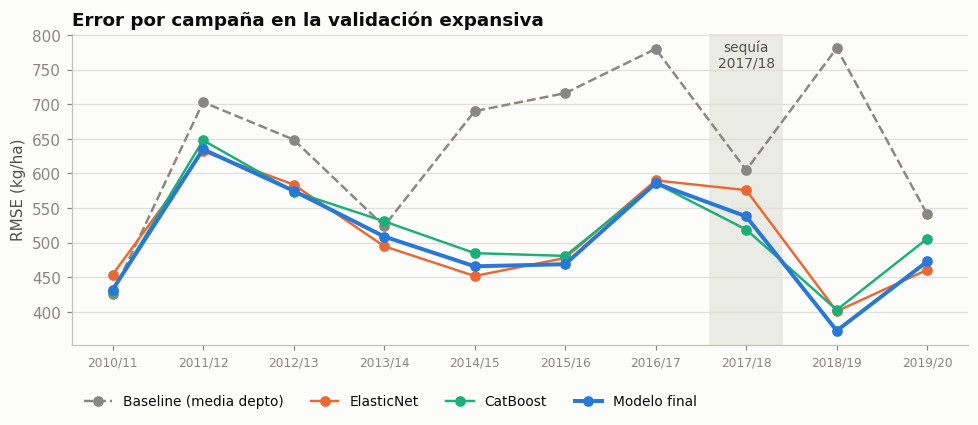

In [15]:
fig, ax = plt.subplots(figsize=(9, 4))
for col in comp.columns:
    nombre_color = "Baseline" if col.startswith("Baseline") else col
    ls = "--" if col.startswith("Baseline") else "-"
    ax.plot(comp.index, comp[col], ls, marker="o", color=COLORES[nombre_color], label=col,
            lw=2.6 if col == "Modelo final" else 1.6, zorder=3 if col == "Modelo final" else 2)
ax.axvspan(2016.6, 2017.4, color="#e1e0d9", alpha=.6, zorder=0)
ax.text(2017, ax.get_ylim()[1] * .99, "sequía\n2017/18", ha="center", va="top", fontsize=9, color="#52514e")
ax.set_xticks(comp.index, [f"{a}/{(a + 1) % 100:02d}" for a in comp.index], rotation=0, fontsize=8)
ax.set_ylabel("RMSE (kg/ha)")
ax.set_title("Error por campaña en la validación expansiva")
ax.legend(ncol=4, loc="upper left", bbox_to_anchor=(0, -0.12), fontsize=9)
plt.tight_layout(); plt.show()

### El sesgo en la sequía: el dato clave para el negocio

In [16]:
clave = ["Baseline: media del depto", "ElasticNet ajustado con Optuna", "CatBoost ajustado con Optuna",
         "LightGBM ajustado con Optuna", FINAL]
t = pd.DataFrame(filas).drop_duplicates("modelo", keep="last").set_index("modelo").loc[clave]
t[["rmse_cv", "mae_cv", "sesgo", "rmse_2017_sequia", "sesgo_sequia", "mejora_pct"]].round(1)

,rmse_cv,mae_cv,sesgo,rmse_2017_sequia,sesgo_sequia,mejora_pct
modelo,,,,,,
Baseline: media del depto,650.6,530.6,-241.9,605.1,173.3,0.0
ElasticNet ajustado con Optuna,516.9,416.8,-43.7,576.4,246.1,20.5
CatBoost ajustado con Optuna,520.6,415.3,-58.1,518.7,128.7,20.0
LightGBM ajustado con Optuna,521.7,417.2,-41.6,560.6,175.4,19.8
Promedio ElasticNet + CatBoost,510.6,408.8,-50.9,538.3,187.4,21.5


**Lectura:** en años normales todos los modelos tienen sesgo levemente negativo (predicen un poco de menos). Pero **en la sequía todos predicen de más**: el modelo "no termina de creer" que el año viene tan malo.

Para una aseguradora **sobreestimar el rinde en sequía es el error caro**: se reserva de menos justo el año en que hay que pagar. Por eso, además del RMSE general, miramos el sesgo en sequía:

- ElasticNet solo: el que más sobreestima en sequía (al ser muy regularizado, "no se anima" a predecir caídas grandes).
- CatBoost: el que menos sobreestima.
- **El promedio queda en el medio en sequía y tiene el mejor RMSE y MAE generales.**

## 8. Ranking general y decisión

In [17]:
ranking = (pd.DataFrame(filas).drop_duplicates("modelo", keep="last")
           .sort_values("rmse_cv")[["seccion"] + COLS].round(1).reset_index(drop=True))
ranking.head(15)

,seccion,modelo,rmse_cv,mae_cv,sesgo,rmse_2017_sequia,sesgo_sequia,mejora_pct
0,7 ensambles,Promedio ElasticNet + CatBoost,510.6,408.8,-50.9,538.3,187.4,21.5
1,7 ensambles,Promedio ElasticNet + LightGBM,510.8,409.7,-42.6,561.5,210.8,21.5
2,7 ensambles,Promedio ElasticNet + CatBoost + LightGBM,511.6,409.2,-47.8,543.8,183.4,21.4
3,7 ensambles,Promedio ElasticNet + CatBoost + XGBoost,513.2,410.7,-47.0,539.3,184.1,21.1
4,7 ensambles,Promedio ElasticNet + LightGBM + XGBoost,513.2,410.9,-41.5,554.1,199.7,21.1
5,7 ensambles,Promedio ElasticNet + XGBoost,513.4,411.5,-41.5,554.8,211.8,21.1
6,7 ensambles,Promedio ElasticNet + CatBoost + LightGBM + XGBoost,513.7,410.9,-45.7,543.3,181.9,21.0
7,4 features,Lasso + rezagos,516.9,417.1,-45.3,569.4,234.3,20.5
8,6 optuna,ElasticNet ajustado con Optuna,516.9,416.8,-43.7,576.4,246.1,20.5
9,5 seleccion,Lasso solo vegetativo + floración,517.3,415.6,-59.8,583.3,246.6,20.5


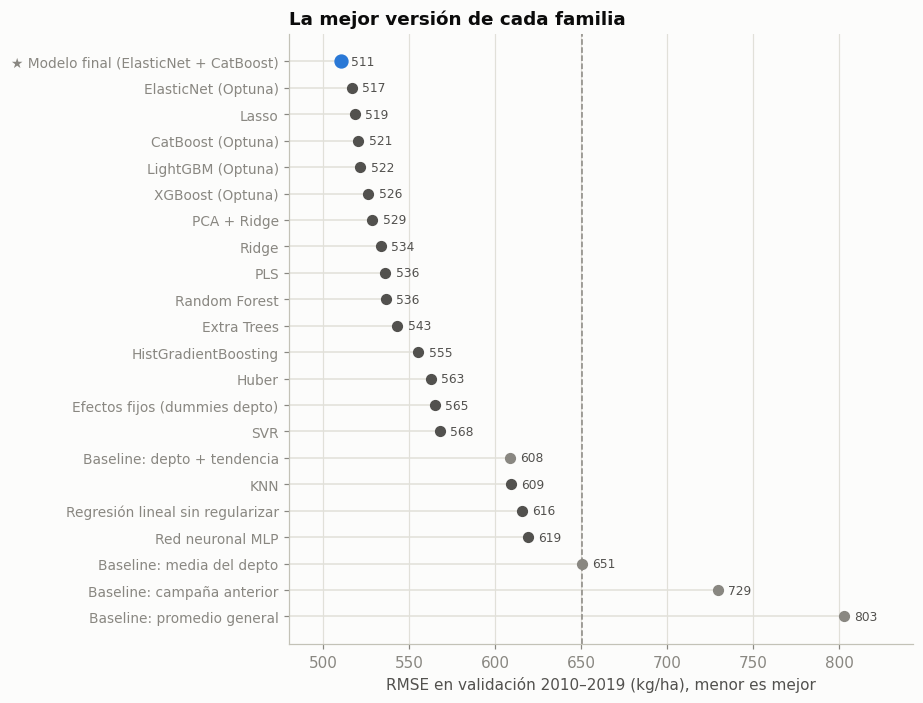

In [18]:
# Un punto por familia (su mejor versión). Puntos y no barras: así el eje no necesita arrancar en 0.
FAMILIAS = {
    "★ Modelo final (ElasticNet + CatBoost)": FINAL,
    "ElasticNet (Optuna)": "ElasticNet ajustado con Optuna", "CatBoost (Optuna)": "CatBoost ajustado con Optuna",
    "LightGBM (Optuna)": "LightGBM ajustado con Optuna", "XGBoost (Optuna)": "XGBoost ajustado con Optuna",
    "Lasso": "Lasso (a=0.012)", "PCA + Ridge": "PCA(20) + Ridge", "Ridge": "Ridge (a=3000)",
    "PLS": "PLS (4 componentes)", "Random Forest": "Random Forest", "Extra Trees": "Extra Trees",
    "HistGradientBoosting": "HistGradientBoosting", "Huber": "Huber robusta (a=1000)",
    "Efectos fijos (dummies depto)": "Efectos fijos: Ridge + dummies depto (crudo)", "SVR": "SVR (C=0.1)",
    "Baseline: depto + tendencia": "Baseline: depto + tendencia", "KNN": "KNN (k=25, residuo)",
    "Regresión lineal sin regularizar": "Regresión lineal sin regularizar", "Red neuronal MLP": "Red neuronal MLP (64-32, residuo)",
    "Baseline: media del depto": "Baseline: media del depto", "Baseline: campaña anterior": "Baseline: campaña anterior",
    "Baseline: promedio general": "Baseline: promedio general",
}
rk = ranking.drop_duplicates("modelo").set_index("modelo").rmse_cv
fam = pd.Series({k: rk[v] for k, v in FAMILIAS.items()}).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8.5, 6.5))
for y, (nombre, v) in enumerate(fam.items()):
    c = (COLORES["Modelo final"] if nombre.startswith("★") else
         COLORES["Baseline"] if nombre.startswith("Baseline") else "#52514e")
    ax.plot([fam.min() - 30, v], [y, y], color="#e1e0d9", lw=1, zorder=1)
    ax.scatter(v, y, s=70 if nombre.startswith("★") else 40, color=c, zorder=3)
    ax.text(v + 6, y, f"{v:.0f}", va="center", fontsize=8, color="#52514e")
ax.set_yticks(range(len(fam)), fam.index, fontsize=9)
ax.axvline(BASE, color=COLORES["Baseline"], ls="--", lw=1)
ax.set_xlim(fam.min() - 30, fam.max() + 40)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_xlabel("RMSE en validación 2010–2019 (kg/ha), menor es mejor")
ax.set_title("La mejor versión de cada familia")
plt.tight_layout(); plt.show()

### Decisión: **promedio de ElasticNet + CatBoost** (target relativo, hiperparámetros de Optuna)

1. **Mejor RMSE y MAE de la validación** (≈ 511 y ≈ 409 kg/ha), **≈ 21 % mejor que el baseline**.
2. **Consistente:** la combinación "lineal + CatBoost" salió primera en todas las rondas en que se probó, con planteos distintos.
3. **Mejor que el ElasticNet solo en la sequía**, que es donde se juega la plata de la aseguradora.
4. **Se explica en una frase:** un modelo lineal que capta el efecto promedio del clima, más un modelo de árboles que capta las combinaciones extremas, promediados mitad y mitad.

**Advertencias honestas:**
- La ventaja sobre el ElasticNet solo es **chica** (≈ 7 kg/ha, gana en 6 de 10 años): está dentro del ruido. Lo que inclina la balanza es el comportamiento en sequía.
- Los números con Optuna son **un poco optimistas** porque los hiperparámetros se eligieron con esta misma validación.
- **Todos los modelos sobreestiman en sequía.** Es una limitación a declarar.

El modelo elegido está definido en `comun.py` → `modelo_final()`. Se entrena y guarda en **`03_entrenar_final.ipynb`** y se evalúa una única vez en el test en **`04_aplicar_test.ipynb`**.

In [19]:
salida = RAIZ / "resultados"
salida.mkdir(exist_ok=True)
ranking.to_csv(salida / "seleccion_modelos.csv", index=False)
comp.to_csv(salida / "validacion_por_anio_modelo_final.csv")
print("Guardado en", salida)

Guardado en C:\Users\Ezequiel\OneDrive - ITBA\Escritorio\ITBA 2026 2Q\Análisis Predictivo\Final\resultados
